# Starting the harness with deep agent from LangGraph

In [ ]:

import os
from deepagents import create_deep_agent
from langchain_openai import ChatOpenAI

MODEL = "glm-5.3-flash"

model = ChatOpenAI(
    model=MODEL,
    api_key=os.environ["ZAI_API_KEY"],
    base_url="https://api.z.ai/api/coding/paas/v4",
)

harness = create_deep_agent(model=model)



# Invoking the base harness as a regular user - No context added

In [ ]:
result = harness.invoke({
    "messages":[{"role": "user", "content":"hello"}]
    })

print(result["messages"][-1].content)

## Adding context to the agent harness

In [ ]:
from deepagents.backends import FilesystemBackend

references = { 
            "backend": FilesystemBackend(root_dir="context"),
            "memory":["/AGENTS.md"],
            "skills":["/skills/company_wide/", "skills/team_wide/"],
            "middleware":[],
            "subagents":[]
            }

harness = create_deep_agent(
    model=model,
    system_prompt="Return drafts and findings in the chat",
    
    # references - Need to setup the backend,
    **references
    )

## Invoking the harness as a regular user - With context and skills

In [ ]:
result = harness.invoke({
    "messages":[{"role":"user", "content":"What is devloot?"}]
    })

print(result["messages"][-1].content)

## Adding tools to the harness - We need a middleware to add specific behavior at specific point in the agent's loop - Before the model call, after the model call etc.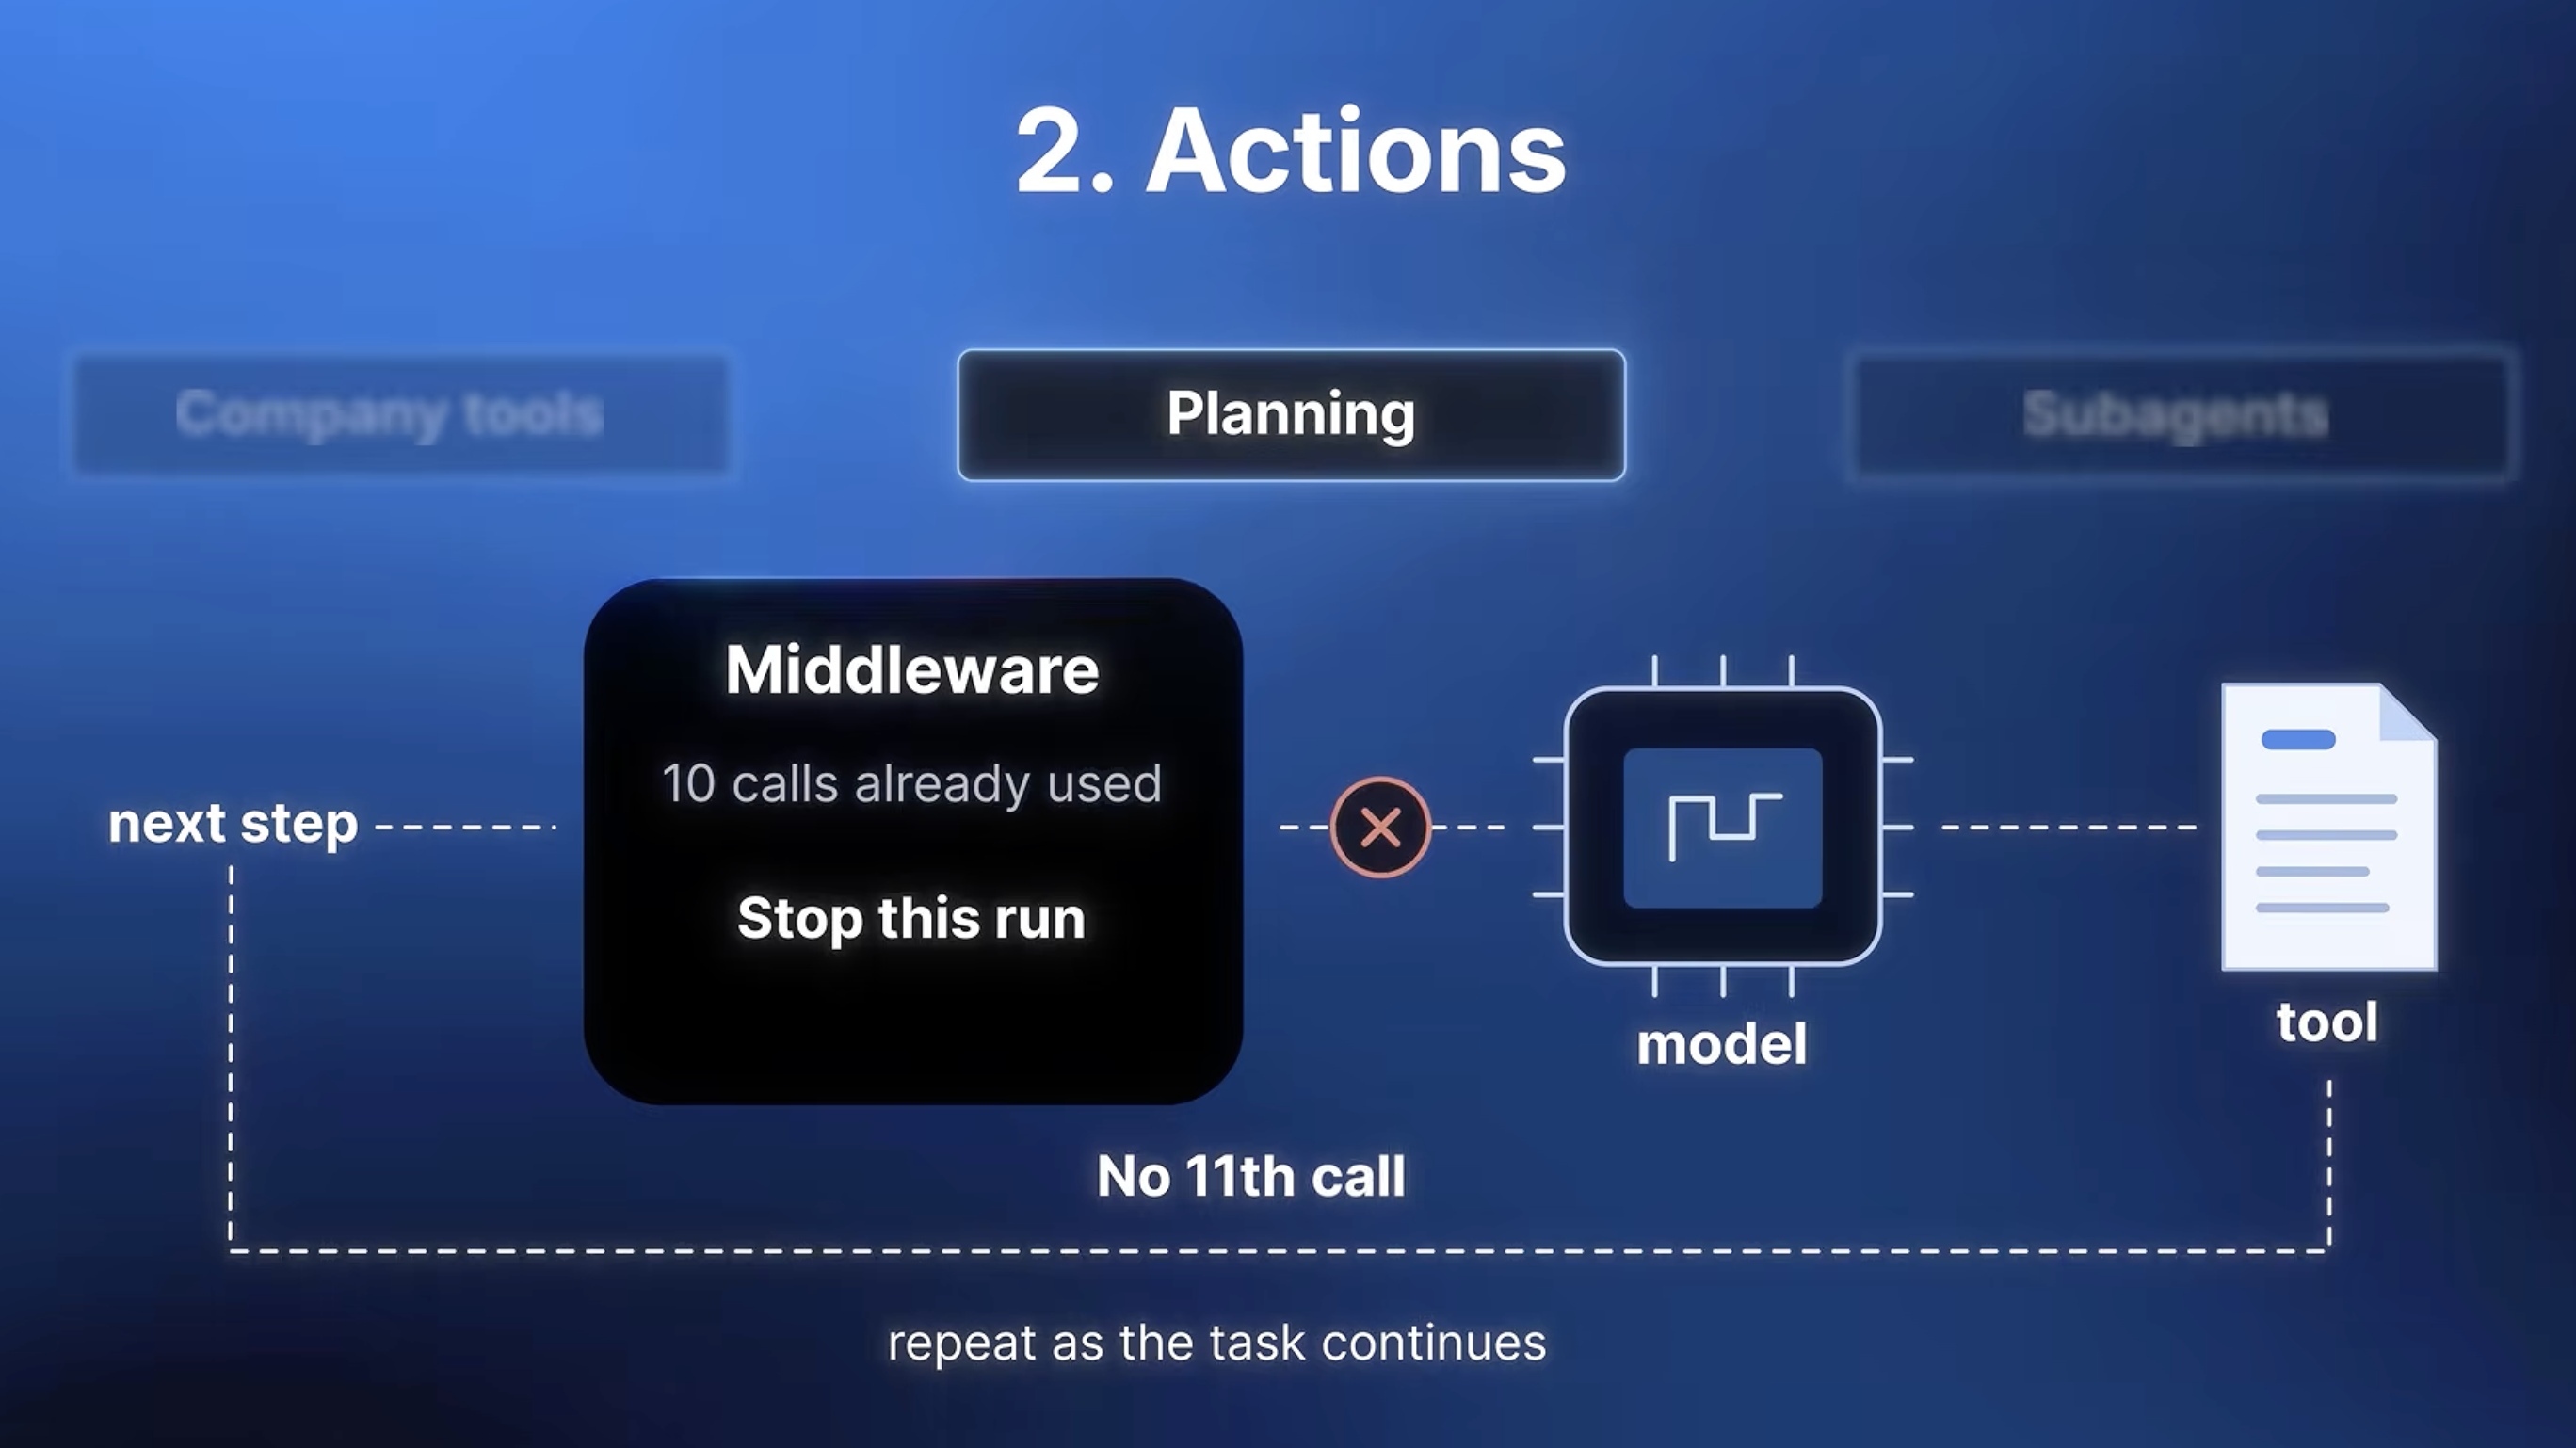

In [ ]:
from langchain.agents.middleware import ModelCallLimitMiddleware, TodoListMiddleware

agent_middleware = [ModelCallLimitMiddleware(run_limit=10, exit_behavior="end"), TodoListMiddleware()]

references["middleware"] = agent_middleware

## Another optimization we can add is using subagents - Its usually used for paralelization and context cleaness so the context is isolated on the subagent that needs it not on the orchestrator agent
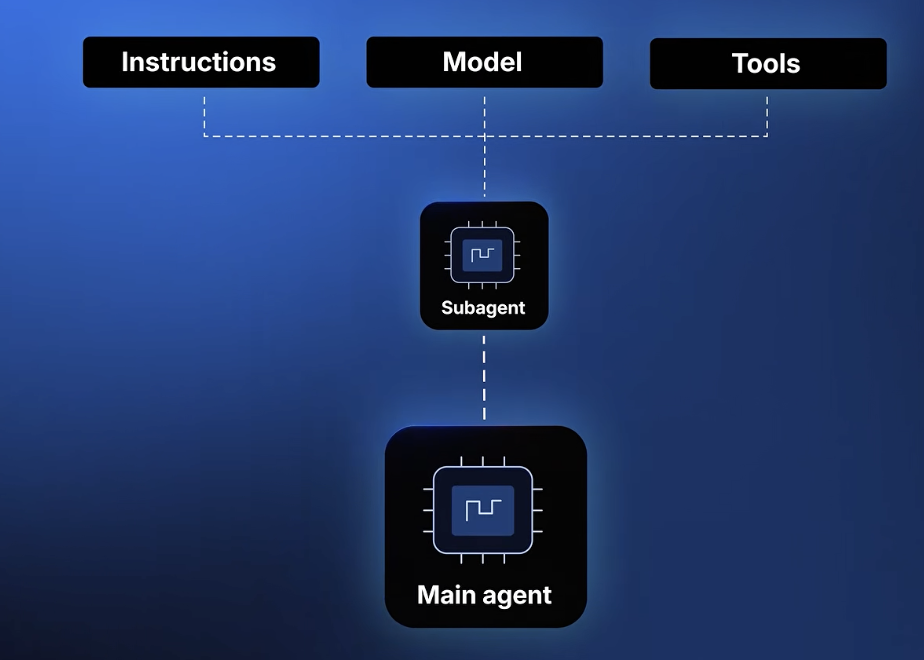

In [ ]:

## Import the tools that the sub agent will have access to
from tools.customer import user_brief

## Setup the sub agent
def proposal_reviewer(model, lookup):
    """Review customer evidence without access to proposal sending"""
    return {
        "name": "proposal-reviewer",
        "description": " Review a proposal against customer facts; flag unsupported commitments",
        "system_prompt": "Lookup the user. Return evidence, assumptions and corrections",
        "model": model,
        "tools": [lookup],
        "middleware": [ModelCallLimitMiddleware(run_limit=4, exit_behavior="end")]
    }
    
    
references["subagents"] = [
    proposal_reviewer(model, user_brief)
]
reviewer_model = model


## Setup the harness with the actions - Tools, middleware and subagents


In [ ]:
reviewer = proposal_reviewer(model, user_brief)
references["tools"] = [user_brief]

harness = create_deep_agent(
    model=model,
    system_prompt="Return drafts and findings in the chat",
    **references,
)

result = harness.invoke({"messages": [{"role": "user", "content": "Draft a proposal for sindresorhus"}]})
print(result["messages"][-1].content)


## Adding boundaries to our harness - Guardrails, permissions and approvals so the user doesn't go savage - Where to stop and get some approval
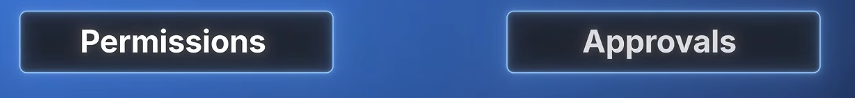

#### Lets start with permissions - Our harness may involve financial data, customer data, engineering data etc. but let's say we don't want to allow engineers to have access to the financial data. That is where we need to set the proper permissions for our harness - Enforce what roles have access to what 

In [ ]:
from types import SimpleNamespace

company = {"access":{}}

company["access"] = {"sales":{"user_brief"}}

### We can add file permissions too - Meaning what kind of access the employee have - write, read and others

In [ ]:
from deepagents.middleware.filesystem import FilesystemPermission

file_permissions = [
    FilesystemPermission(
        operations=["write"],
        paths=["/company/**","/skills/**"],
        mode="deny")]

## Now lets create our harness with boundaries - The third component of agentic harness engineering

`interrupt_on` pauses before the tool executes; it does not create a user interface.
The approval request is in `result["__interrupt__"]`, not the last message's content.
The notebook must display it, collect a decision, and resume with `Command` using
the same checkpointer and `thread_id`.

This example asks for approval before **looking up customer data**, not before
accepting or sending a proposal. `InMemorySaver` retains paused runs only while
this kernel is alive. Each execution of the next cell starts a fresh run.


In [ ]:

harness = create_deep_agent(
    model=model,
    system_prompt="Return drafts and findings in the chat",
    **references,
    interrupt_on={"user_brief": {"allowed_decisions": ["approve", "reject"]}},
)

result = harness.invoke({"messages": [{"role": "user", "content": "Draft a proposal for sindresorhus"}]})
print(result["messages"][-1].content)


## Now lets make our harness persist the conversation I call it give memory - This is the fourth component of Agentic harness engineering and its pretty important

In [ ]:
# We will use sqlite as the persistence layer for this application
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver
from pathlib import Path
ROOT = Path.cwd()

checkpoint_path = ROOT / "checkpoint/notebook.sqlite"

checkpoint_path.parent.mkdir(exist_ok=True)

connection = sqlite3.connect(checkpoint_path, check_same_thread=False)

saver = SqliteSaver(connection)

## Context Management - We will summarize 12,000 tokens and retain six recent messages on the memory

In [ ]:
from readline import backend

from deepagents.middleware.summarization import SummarizationMiddleware
backend=references["backend"]


agent_middleware.extend([
    SummarizationMiddleware(
        model=model,
        backend=backend,
        trigger=("tokens", 12000),
        keep=("messages", 6),
        trim_tokens_to_summarize=None
        )
    ])